# N4. Mutational signature 처음부터 끝까지: 변이 목록에서 signature 까지

**목표**
- 체세포 SNV 하나가 96칸 중 한 칸이 되는 과정을 직접 코드로 따라갑니다.
- 96 × 표본 catalog 행렬을 NMF 로 "signature(재료) × 노출량(양)"으로 나누고, 정답과 맞춰 봅니다.
- 이미 아는 signature 로 노출량만 다시 구하는 방법(NNLS 배정)과 de novo 추출을 비교합니다.
- 변이 수가 적은 시료가 왜 흔들리는지, 실제 도구(SigProfilerExtractor·SigProfilerAssignment)가 무엇을 더 하는지 봅니다.

**이 노트북이 답하는 질문**: VCF 에서 시작해 "이 종양에는 어떤 돌연변이 과정이 얼마나 작동했나"까지 가려면 행렬을 어떻게 만들고 어떻게 나누나?

**이어지는 노트북**: NMF 알고리즘 자체는 N2, k 고르기는 N3, NNLS 는 [행렬 M3](../linear-algebra-matrices/lab03_least-squares.ipynb) 에서 더 자세히 봅니다.

이 노트북의 signature 는 모두 **모양만 비슷하게 손으로 만든 장난감**입니다. COSMIC 값을 옮기지 않았습니다.

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 팔레트: Okabe-Ito. 성분(signature·program) 색은 N1–N5 공통 순서,
# 96칸 치환 색은 SigProfilerPlotting 관례색 [7], 핵심 메시지는 자주색 하나.
import logging, math, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from scipy.optimize import linear_sum_assignment, nnls
from scipy.stats import ranksums
from sklearn.decomposition import NMF
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import silhouette_samples

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 12)

COL = dict(ink="#222222", muted="#6B7280", grid="#E5E7EB", none="#D1D5DB", shade="#F3F4F6",
           highlight="#CC79A7", ok="#009E73", true="#374151",
           data="#6B7280", facP="#1F2937", facE="#78716C", metric="#111827", metric2="#9CA3AF")
# data = 데이터 행렬(M, X) 회색 · facP/facE = 수식의 두 인자(성분 색과 겹치지 않는 무채색) · metric = 안정성·오차 같은 지표 선
COMP = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#56B4E9", "#F0E442", "#6B7280", "#9CA3AF", "#374151", "#BBBBBB"]   # N1–N5 공통(_palette.py): 성분 1, 2, 3 ...

def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white"})

def panel(ax, letter, title):
    ax.set_title(f"{letter}   {title}")

def note(ax, x, y, text, **kw):
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)

def callout(ax, x, y, text, **kw):
    """핵심 메시지 한 줄: 자주색 굵은 글씨, 흰 바탕"""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, **kw)

def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)

def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.03):
    """수식 조각 그림. parts = [(mathtext, 색 또는 None, 이름표 또는 None), ...]"""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); x = 0.0; items = []
    for tex, color, label in parts:
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="left", color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lw = 0.0
        if label:
            lt = ax.text(0, 0, label, fontsize=9.5, fontweight="semibold", transform=ax.transAxes)
            lw = lt.get_window_extent(renderer=r).transformed(inv).width; lt.remove()
        slot = max(bb.width, lw)
        items.append((t, bb, color, label, x + (slot - bb.width) / 2)); x += slot + gap
    shift = (1 - (x - gap)) / 2
    for t, bb, color, label, x0 in items:
        t.set_x(x0 + shift)
        if color:
            ax.add_patch(FancyBboxPatch((x0 + shift - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if label:
            ax.text(x0 + shift + bb.width / 2, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                    color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)

def show_formula(parts, title=None, height=1.5, width=11):
    fig, ax = plt.subplots(figsize=(width, height))
    formula_strip(ax, parts)
    if title:
        ax.text(0.5, 1.05, title, ha="center", va="bottom", fontsize=11.5, fontweight="semibold", transform=ax.transAxes)
    plt.show()

def concept_map(nodes, edges, title="Concept map", size=(11, 3.2)):
    """nodes = {key: (x, y, text, color)}, edges = [(from, to, label)]"""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_axis_off()
    boxes = {}
    for k, (x, y, text, c) in nodes.items():
        boxes[k] = ax.text(x, y, text, ha="center", va="center", fontsize=10, color=COL["ink"], zorder=3,
                           bbox=dict(boxstyle="round,pad=0.45", facecolor=c, alpha=0.22 if c != "white" else 1,
                                     edgecolor=c if c != "white" else COL["muted"], linewidth=1.0))
    fig.canvas.draw(); r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); ext = {}
    for k, t in boxes.items():
        bb = t.get_bbox_patch().get_window_extent(r).transformed(inv); ext[k] = (bb.x0, bb.y0, bb.x1, bb.y1)

    def edge_point(k, dx, dy):
        x0, y0, x1, y1 = ext[k]; cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        hw, hh = (x1 - x0) / 2 + 0.008, (y1 - y0) / 2 + 0.02
        s = min(hw / abs(dx) if dx else 1e9, hh / abs(dy) if dy else 1e9)
        return cx + dx * s, cy + dy * s

    for a, b, lab in edges:
        (ax0, ay0, ax1, ay1), (bx0, by0, bx1, by1) = ext[a], ext[b]
        dx, dy = (bx0 + bx1) / 2 - (ax0 + ax1) / 2, (by0 + by1) / 2 - (ay0 + ay1) / 2
        p0 = edge_point(a, dx, dy); p1 = edge_point(b, -dx, -dy)
        ax.annotate("", xy=p1, xytext=p0, xycoords="axes fraction", textcoords="axes fraction",
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.0, mutation_scale=12, shrinkA=0, shrinkB=0), zorder=2)
        if lab:
            note(ax, (p0[0] + p1[0]) / 2, (p0[1] + p1[1]) / 2 + 0.05, lab, ha="center", fontsize=8.5, transform=ax.transAxes)
    ax.set_title(title)
    plt.show()

# ---- 96칸 ----
SUBS = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]
TYPE_COL = {"C>A": "#03BDEF", "C>G": "#010101", "C>T": "#E42926", "T>A": "#CBCACA", "T>C": "#A2CF63", "T>G": "#ECC7C5"}  # [7]
BASES = "ACGT"
CHANNELS = [f"{a}[{s}]{b}" for s in SUBS for a in BASES for b in BASES]     # SigProfiler 그림 순서(치환 → 5' → 3')
COMP_RC = str.maketrans("ACGT", "TGCA")

def revcomp(s):
    return s.translate(COMP_RC)[::-1]

def classify(context, ref, alt):
    """3염기 문맥(5'-REF-3'), REF, ALT → 'A[C>T]G' 같은 96칸 이름. 퓨린(A, G) 기준이면 반대 가닥으로 뒤집는다."""
    assert context[1] == ref
    if ref in "AG":
        context, ref, alt = revcomp(context), ref.translate(COMP_RC), alt.translate(COMP_RC)
    return f"{context[0]}[{ref}>{alt}]{context[2]}"

def plot96(ax, v, ylabel="share of SNVs", top_labels=True):
    v = np.asarray(v, float); x = np.arange(96)
    ax.bar(x, v, color=[TYPE_COL[c[2:5]] for c in CHANNELS], width=0.78, linewidth=0)
    ymax = v.max() * 1.22 if v.max() > 0 else 1
    ax.set_ylim(0, ymax); ax.set_xlim(-0.8, 95.8); ax.set_xticks([])
    for i, s in enumerate(SUBS):
        ax.add_patch(Rectangle((i * 16 - 0.4, ymax * 0.9), 15.8, ymax * 0.05, color=TYPE_COL[s], lw=0))
        if top_labels:
            ax.text(i * 16 + 7.5, ymax * 0.965, s, ha="center", va="bottom", fontsize=9.5, fontweight="semibold", color=COL["ink"])
    ax.set_ylabel(ylabel); ygrid(ax)

def cos_matrix(A, B):
    """열끼리 코사인 유사도. A: 96 × a, B: 96 × b → a × b"""
    A = A / np.linalg.norm(A, axis=0, keepdims=True); B = B / np.linalg.norm(B, axis=0, keepdims=True)
    return A.T @ B

def match(P_ref, P_est):
    """할당 문제로 짝 맞추기: 코사인 합이 가장 큰 1:1 짝. 반환: P_est 의 열 순서, 짝지은 코사인"""
    C = cos_matrix(P_ref, P_est)
    r, c = linear_sum_assignment(C, maximize=True)
    return c, C[r, c]

def nmf_kl(M, k, seed, max_iter=1500, init="random"):
    """M: 96 × n (SigProfiler 방향). scikit-learn 은 표본 × 특징이라 M.T 를 넣고 결과를 다시 돌린다.
    반환 P: 96 × k (열 합 1), E: k × n (변이 개수 단위)"""
    model = NMF(n_components=k, beta_loss="kullback-leibler", solver="mu", init=init,
                max_iter=max_iter, tol=1e-6, random_state=seed)
    W = model.fit_transform(M.T.astype(float))      # n × k  = Eᵀ
    H = model.components_                           # k × 96 = Pᵀ
    P = H.T; s = P.sum(axis=0); P = P / s; E = (W * s).T
    return P, E

def refit_nnls(M, P):
    """표본마다 NNLS: m ≈ P a, a ≥ 0 [8]"""
    return np.column_stack([nnls(P, M[:, j])[0] for j in range(M.shape[1])])

def rel_error(M, P, E):
    return np.linalg.norm(M - P @ E) / np.linalg.norm(M)

def cap_100x(M, n_channels=96):
    """100X 정규화: 총 변이 수가 채널 수의 100배를 넘는 표본(열)을 그 값으로 줄인다 [4]"""
    cap = 100 * n_channels; M = M.astype(float).copy(); s = M.sum(axis=0); big = s > cap
    M[:, big] = M[:, big] / s[big] * cap
    return M

def stability_scan(M, ks, reps, seed=0, resample=True, max_iter=1200, norm=None):
    """k 마다: M 을 reps 번 (포아송 재표집 → 정규화 norm, 실제 도구와 같은 순서 [4]) 분해 →
    첫 결과에 맞춰 짝 맞추기를 3번 되풀이해 군집 → 성분별 평균 silhouette(코사인 거리) = 안정성,
    군집 중심 P 로 원래 M 을 NNLS 로 다시 맞춘 E 와 상대 오차"""
    rng = np.random.default_rng(seed); out = {}
    for k in ks:
        sigs = []
        for r in range(reps):
            Mr = rng.poisson(M) if resample else M
            if norm is not None:
                Mr = norm(Mr)
            sigs.append(nmf_kl(Mr, k, seed=int(rng.integers(1e9)), max_iter=max_iter)[0])
        ref = sigs[0]
        for _ in range(3):
            aligned = [P[:, match(ref, P)[0]] for P in sigs]
            ref = np.mean(aligned, axis=0); ref = ref / ref.sum(axis=0)
        X = np.concatenate([P.T for P in aligned]); lab = np.tile(np.arange(k), reps)
        sil = silhouette_samples(X, lab, metric="cosine")
        per = np.array([sil[lab == j].mean() for j in range(k)])
        E = refit_nnls(M, ref)
        out[k] = dict(P=ref, E=E, stab=per.mean(), stab_min=per.min(), per=per, err=rel_error(M, ref, E))
    return out

def choose_k(scan, avg=0.80, low=0.20, gain=0.01):
    """이 노트북의 단순 규칙: 안정한 k(평균 ≥ 0.80, 가장 낮은 성분 ≥ 0.20 [4]) 중에서,
    k 를 하나 늘렸을 때 상대 오차가 1% 포인트 넘게 줄어드는 동안만 올라간다."""
    ks = sorted(scan); stable = [k for k in ks if scan[k]["stab"] >= avg and scan[k]["stab_min"] >= low]
    best = stable[0] if stable else ks[0]
    for k in stable[1:]:
        if scan[best]["err"] - scan[k]["err"] > gain:
            best = k
        else:
            break
    return best

def choose_k_wilcoxon(scan, M, avg=0.80, low=0.20, alpha=0.05):
    """SigProfilerExtractor 의 WGS 규칙 [4]: 안정한 k 중 가장 큰 k 의 표본별 재구성 오차와,
    그보다 작은 안정한 k 의 오차를 큰 쪽부터 차례로 Wilcoxon 순위합 검정으로 비교한다.
    p < 0.05 가 처음 나오면 멈추고, 그 전까지 p ≥ 0.05 였던 가장 작은 k 를 고른다.
    (표본별 오차는 논문이 식을 적지 않아 여기서는 ||m - Pe|| / ||m|| 로 둔다)"""
    stable = sorted(k for k in scan if scan[k]["stab"] >= avg and scan[k]["stab_min"] >= low)
    if not stable:
        return min(scan)
    def per_sample(k):
        return np.linalg.norm(M - scan[k]["P"] @ scan[k]["E"], axis=0) / np.linalg.norm(M, axis=0)
    best = stable[-1]
    for k in reversed(stable[:-1]):
        if ranksums(per_sample(k), per_sample(stable[-1])).pvalue < alpha:
            break
        best = k
    return best

apply_theme()

## 개념 지도

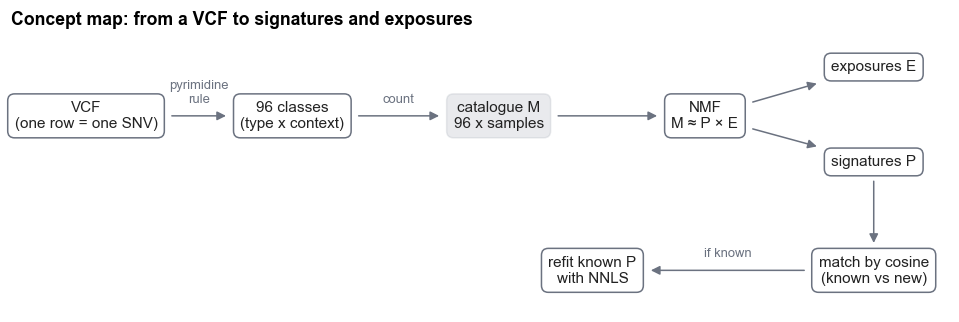

In [2]:
concept_map({
    "vcf": (0.08, 0.72, "VCF\n(one row = one SNV)", "white"),
    "cls": (0.30, 0.72, "96 classes\n(type x context)", "white"),
    "cat": (0.52, 0.72, "catalogue M\n96 x samples", "#9CA3AF"),
    "nmf": (0.74, 0.72, "NMF\nM ≈ P × E", "white"),
    "exp": (0.92, 0.90, "exposures E", "white"),
    "sig": (0.92, 0.55, "signatures P", "white"),
    "cos": (0.92, 0.15, "match by cosine\n(known vs new)", "white"),
    "nnls": (0.62, 0.15, "refit known P\nwith NNLS", "white"),
}, [("vcf", "cls", "pyrimidine\nrule"), ("cls", "cat", "count"), ("cat", "nmf", ""), ("nmf", "sig", ""), ("nmf", "exp", ""),
    ("sig", "cos", ""), ("cos", "nnls", "if known")], title="Concept map: from a VCF to signatures and exposures")

**그림에서 볼 것**: 왼쪽 위에서 오른쪽으로 갑니다. 변이 하나하나 → 96칸 중 한 칸 → 표본마다 96칸 개수를 세운 행렬 M → NMF 로 signature(P)와 노출량(E)으로 나누기.
새로 뽑은 signature 를 이미 아는 것과 코사인으로 맞춰 보고, 아는 것이면 NNLS 로 노출량만 다시 구할 수도 있습니다(아래 줄).

## 먼저 알아 둘 것

### 1. 체세포 SNV 와 치환 6종류: 왜 "피리미딘 기준"인가

**한 줄 정의**: 염기 치환(SNV)을 바뀐 자리의 **피리미딘(C 또는 T) 쪽에서 읽어** C>A, C>G, C>T, T>A, T>C, T>G 의 6종류로만 부릅니다 [1].

**왜 필요한가**: DNA 는 두 가닥이 짝(A–T, G–C)을 이룹니다. 위 가닥에서 G>T 가 생겼다면 아래 가닥에서는 같은 사건이 C>A 로 보입니다.
같은 사건을 두 이름으로 세면 칸이 12개로 쪼개지고 개수가 나뉩니다. 그래서 늘 C 나 T 가 있는 가닥에서 읽어 한 이름으로 셉니다.

**숫자로 따라가기**

| 위 가닥에서 본 변화 | 피리미딘 가닥에서 읽기 | 이름 |
|---|---|---|
| G>T | C>A | C>A |
| A>G | T>C | T>C |
| C>T | (이미 피리미딘) | C>T |
| G>A | C>T | C>T |

12가지(4 × 3)가 짝을 지어 6가지가 됩니다.

### 2. 3염기 문맥과 96칸

**한 줄 정의**: 바뀐 염기의 바로 앞(5′)과 뒤(3′) 염기까지 함께 적은 이름입니다. 예: `T[C>T]A` = "T C A 에서 가운데 C 가 T 로".

**왜 필요한가**: 같은 C>T 라도 어떤 과정은 CpG(뒤가 G)에서, 어떤 과정은 TCA·TCT 에서 주로 생깁니다. 앞뒤 염기를 보면 같은 치환을 일으키는 서로 다른 과정을 가를 수 있습니다 [1].

**숫자로 따라가기**: 치환 6종류 × 앞 염기 4 × 뒤 염기 4 = **96칸**. Alexandrov 등은 이 96칸 분류가 "같은 치환을 일으키지만 문맥이 다른 signature 를 가르는 데 특히 쓸모 있다"고 적었습니다 [1].

아래는 장난감 "유전체" 한 줄과 변이 6개를 가진 작은 VCF 같은 표입니다. 이 표를 96칸 이름으로 바꾸는 코드를 직접 씁니다.

In [3]:
genome = "ATGCAACGTTATCAGTTAGCTTACGGATCTACGATTCTGCA"      # 장난감 참조 서열 41염기(1번부터 셈)
vcf = pd.DataFrame({
    "CHROM": ["toy"] * 6,
    "POS":   [7, 13, 19, 25, 31, 37],
    "REF":   ["C", "C", "G", "G", "A", "C"],
    "ALT":   ["T", "T", "T", "A", "G", "G"],
})
vcf["context"] = [genome[p - 2: p + 1] for p in vcf.POS]          # 5'-REF-3' (POS 는 1번부터)
vcf["class96"] = [classify(c, r, a) for c, r, a in zip(vcf.context, vcf.REF, vcf.ALT)]
print("VCF 같은 표: shape", vcf.shape)
vcf

VCF 같은 표: shape (6, 6)


,CHROM,POS,REF,ALT,context,class96
0,toy,7,C,T,ACG,A[C>T]G
1,toy,13,C,T,TCA,T[C>T]A
2,toy,19,G,T,AGC,G[C>A]T
3,toy,25,G,A,CGG,C[C>T]G
4,toy,31,A,G,TAC,G[T>C]A
5,toy,37,C,G,TCT,T[C>G]T


In [4]:
# 손으로 확인: 퓨린(A·G) 기준 변이는 반대 가닥으로 읽힌다
assert classify("ACG", "C", "T") == "A[C>T]G"          # CpG 의 C>T
assert classify("AGC", "G", "T") == "G[C>A]T"          # 위 가닥 AGC 의 G>T  →  아래 가닥 GCT 의 C>A
assert classify("CGG", "G", "A") == "C[C>T]G"          # CpG 반대쪽 G>A 도 같은 CpG C>T
assert len(CHANNELS) == 96 and len(set(CHANNELS)) == 96

catalog = pd.Series(0, index=CHANNELS)
for c in vcf.class96:
    catalog[c] += 1
print("이 표본의 96칸 catalog: 길이", len(catalog), "| 개수가 있는 칸:")
print(catalog[catalog > 0])

이 표본의 96칸 catalog: 길이 96 | 개수가 있는 칸:
G[C>A]T    1
T[C>G]T    1
A[C>T]G    1
C[C>T]G    1
T[C>T]A    1
G[T>C]A    1
dtype: int64


**그림에서 볼 것은 없고, 표에서 볼 것**
- 셋째 줄(POS 19, G>T, 문맥 AGC)은 반대 가닥에서 읽어 `G[C>A]T` 가 됩니다. 문맥도 뒤집혀(AGC → GCT) 앞뒤 염기가 바뀝니다.
- 넷째 줄(POS 25, G>A, 문맥 CGG)은 반대 가닥에서 CpG 의 C>T 가 됩니다. 첫째 줄의 `A[C>T]G` 와 같은 "CpG C>T" 무리입니다.

**직접 바꿔 보기**: `vcf` 에 줄을 하나 더해 보세요(예: POS 4, REF 는 `genome[3]` 과 같은 C). 다른 칸이 1 늘어납니다.

### 3. 96칸 그림 읽는 법

**한 줄 정의**: 96칸을 치환 종류별로 16칸씩 묶어 막대로 그린 그림입니다. 색은 SigProfiler 그림에서 흔히 쓰는 관례색입니다 [7].

묶음 안의 16칸은 "앞 염기 A, C, G, T × 뒤 염기 A, C, G, T" 순서입니다. 아래는 이 노트북에서 쓸 장난감 signature 다섯 개입니다.

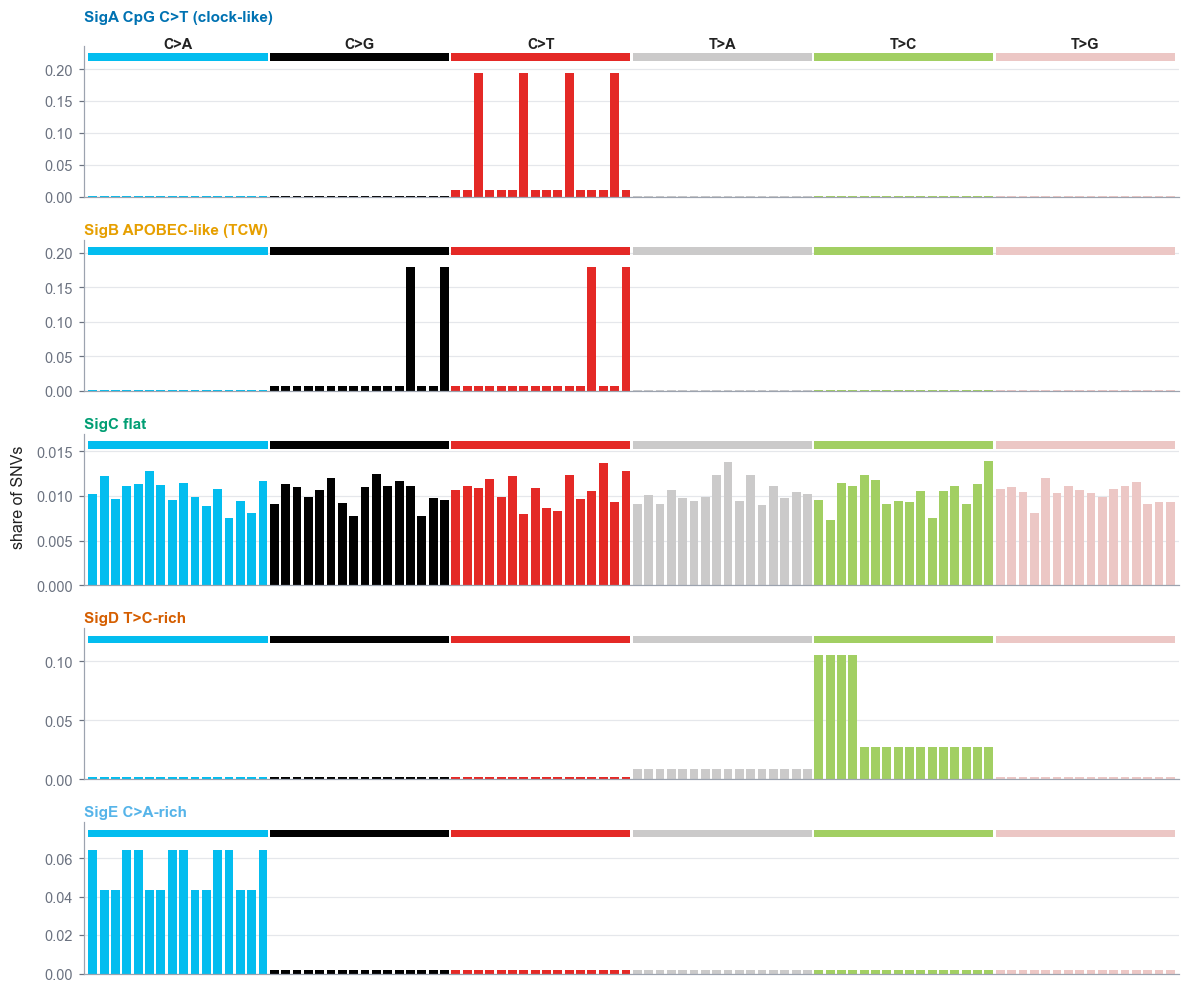

In [5]:
def toy_signatures(seed=11):
    rng = np.random.default_rng(seed)
    def on(pred):
        return np.array([pred(c[0], c[2:5], c[6]) for c in CHANNELS], float)
    base = np.full(96, 0.02)
    sigs = {
        "SigA CpG C>T (clock-like)": base + 3.0 * on(lambda a, s, b: s == "C>T" and b == "G") + 0.15 * on(lambda a, s, b: s == "C>T"),
        "SigB APOBEC-like (TCW)":    base + 2.5 * on(lambda a, s, b: a == "T" and s in ("C>T", "C>G") and b in "AT")
                                         + 0.08 * on(lambda a, s, b: s in ("C>T", "C>G")),
        "SigC flat":                 rng.dirichlet(np.full(96, 30.0)) * 96 * 0.05 + 0.01,
        "SigD T>C-rich":             base + 0.9 * on(lambda a, s, b: s == "T>C" and a == "A") + 0.3 * on(lambda a, s, b: s == "T>C")
                                         + 0.08 * on(lambda a, s, b: s == "T>A"),
        "SigE C>A-rich":             base + 0.5 * on(lambda a, s, b: s == "C>A") + 0.25 * on(lambda a, s, b: s == "C>A" and b in "AT"),
    }
    P = np.column_stack(list(sigs.values())); P = P / P.sum(axis=0)
    return pd.DataFrame(P, index=CHANNELS, columns=list(sigs))

P_true = toy_signatures()
assert np.allclose(P_true.sum(), 1) and (P_true.values > 0).all()

def draw_signatures(P, title_prefix="", cos_vals=None):
    k = P.shape[1]
    fig, axes = plt.subplots(k, 1, figsize=(11, 1.75 * k + 0.4), sharex=True)
    for i, ax in enumerate(np.atleast_1d(axes)):
        plot96(ax, P.iloc[:, i] if hasattr(P, "iloc") else P[:, i], ylabel="", top_labels=(i == 0))
        name = P.columns[i] if hasattr(P, "columns") else f"component {i + 1}"
        extra = f"   (cosine to truth {cos_vals[i]:.3f})" if cos_vals is not None else ""
        ax.set_title(f"{title_prefix}{name}{extra}", fontsize=10, color=COMP[i % len(COMP)], pad=16 if i == 0 else 4)
    fig.supylabel("share of SNVs", fontsize=10.5, color=COL["ink"])
    plt.tight_layout(); plt.show()

draw_signatures(P_true)

**그림에서 볼 것**
- SigA: 빨간 C>T 묶음 안에서 4칸(뒤 염기가 G 인 칸, 즉 CpG)만 높습니다.
- SigB: C>T(빨강)와 C>G(검정) 묶음에서 앞이 T, 뒤가 A·T 인 칸(TCA·TCT)이 높습니다. APOBEC 과 비슷한 모양입니다.
- SigC: 거의 평평합니다. 이런 signature 는 다른 것과 섞이기 쉬워 뽑기 어렵습니다(아래에서 확인).
- SigD: 초록 T>C 묶음, 그중 앞이 A 인 칸이 높습니다. SigE: 하늘색 C>A 묶음이 높습니다.

모두 합이 1인 "96칸에 변이가 떨어질 확률 분포"입니다.

## 4. catalog 행렬과 M ≈ P × E

**한 줄 정의**: 표본마다 96칸 개수를 한 열로 세우면 96 × 표본 행렬 M 이 됩니다. 이것을 signature 행렬 P(96 × k)와 노출량 행렬 E(k × 표본)의 곱으로 근사합니다 [2].

**왜 필요한가**: 한 종양의 변이는 여러 과정(나이, APOBEC, 흡연 등)이 함께 만든 것입니다. M ≈ P × E 는 "각 표본의 96칸 = 과정별 모양(P의 열) × 그 과정이 만든 변이 수(E의 칸)의 합"이라는 가정입니다.

아래에서 장난감 코호트 150명을 만듭니다. 변이 수(burden)는 표본마다 수백~수만 개로 크게 다르고, 실제 개수는 기댓값 P × E 에서 포아송으로 뽑습니다.

In [6]:
def simulate_cohort(P, n=150, seed=7):
    rng = np.random.default_rng(seed)
    k = P.shape[1]
    burden = np.round(np.exp(rng.normal(np.log(3000), 0.9, n))).clip(150, 60000)
    active = np.column_stack([np.ones(n, bool), rng.random(n) < 0.45, np.ones(n, bool), rng.random(n) < 0.35, rng.random(n) < 0.30])
    frac = np.zeros((n, k))
    for j in range(n):
        idx = np.flatnonzero(active[j]); frac[j, idx] = rng.dirichlet(np.full(len(idx), 1.5))
    E = (frac * burden[:, None]).T                                   # k × n, 변이 수 단위
    M = rng.poisson(P.values @ E)                                    # 96 × n, 정수
    names = [f"S{j + 1:03d}" for j in range(n)]
    return (pd.DataFrame(M, index=CHANNELS, columns=names),
            pd.DataFrame(E, index=P.columns, columns=names), burden)

M_df, E_true, burden = simulate_cohort(P_true)
M = M_df.values.astype(float)
print("signature P :", P_true.shape, "(96칸 × signature)")
print("노출량 E    :", E_true.shape, "(signature × 표본)")
print("catalog M  :", M_df.shape, "(96칸 × 표본), 정수 개수")
print("표본당 변이 수: 최소", int(M.sum(0).min()), "| 중앙값", int(np.median(M.sum(0))), "| 최대", int(M.sum(0).max()))
M_df.iloc[:6, :6]

signature P : (96, 5) (96칸 × signature)
노출량 E    : (5, 150) (signature × 표본)
catalog M  : (96, 150) (96칸 × 표본), 정수 개수
표본당 변이 수: 최소 331 | 중앙값 2709 | 최대 22534


,S001,S002,S003,S004,S005,S006
A[C>A]A,6,14,18,10,12,8
A[C>A]C,6,11,28,7,18,7
A[C>A]G,8,10,24,12,7,6
A[C>A]T,6,12,28,9,11,5
C[C>A]A,3,13,20,5,21,7
C[C>A]C,7,16,20,6,18,7


In [7]:
E_true.round(0).astype(int).iloc[:, :6]

,S001,S002,S003,S004,S005,S006
SigA CpG C>T (clock-like),980,2987,392,879,705,432
SigB APOBEC-like (TCW),0,0,0,0,0,305
SigC flat,392,938,1952,467,1288,492
SigD T>C-rich,1632,0,0,0,0,0
SigE C>A-rich,0,0,0,0,0,0


**표에서 볼 것**
- M 의 행 이름은 96칸(`A[C>A]A` …), 열 이름은 표본입니다. Alexandrov 등도 catalog 행렬을 "K(변이 종류 수) × G(유전체 수)" 크기로, 유전체가 열이 되게 정의합니다 [2].
- E 의 칸은 "그 signature 가 그 표본에 만든 변이 수"입니다. 0 인 칸은 그 과정이 그 표본에서 작동하지 않았다는 뜻입니다.

**수식 풀어 읽기**

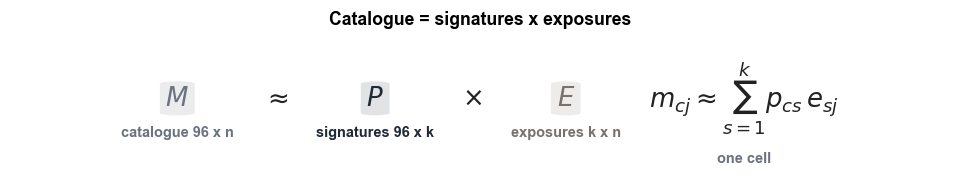

In [8]:
show_formula([
    (r"$M$", COL["data"], "catalogue 96 x n"),
    (r"$\approx$", None, None),
    (r"$P$", COL["facP"], "signatures 96 x k"),
    (r"$\times$", None, None),
    (r"$E$", COL["facE"], "exposures k x n"),
    (r"$m_{cj} \approx \sum_{s=1}^{k} p_{cs}\, e_{sj}$", None, "one cell"),
], title="Catalogue = signatures x exposures")

| 기호 | 소리 내어 읽기 | 뜻 | 그림·표에서 어디 |
|---|---|---|---|
| $m_{cj}$ | "엠 씨 제이" | 표본 j 의 칸 c 에 떨어진 변이 수 | M 표의 한 칸 |
| $p_{cs}$ | "피 씨 에스" | signature s 가 칸 c 에 변이를 떨어뜨릴 확률(열 합 1) | 위 96칸 그림의 막대 하나 |
| $e_{sj}$ | "이 에스 제이" | signature s 가 표본 j 에 만든 변이 수 | E 표의 한 칸 |
| $\sum_{s=1}^{k}$ | "에스가 1부터 k 까지 더하기" | 모든 과정의 몫을 합친다 | — |

**숫자 넣기**: 표본 S001 의 `A[C>T]G` 칸 기댓값 = Σ (SigX 의 그 칸 확률 × S001 의 SigX 노출량).

In [9]:
c = "A[C>T]G"; j = "S001"
parts = P_true.loc[c] * E_true[j]
print(pd.DataFrame({"p_cs": P_true.loc[c].round(4), "e_sj": E_true[j].round(1), "p x e": parts.round(2)}))
print(f"기댓값 합 = {parts.sum():.2f},  실제로 뽑힌 개수(포아송) = {int(M_df.loc[c, j])}")
assert np.isclose(parts.sum(), (P_true.values @ E_true.values)[CHANNELS.index(c), 0])

                             p_cs    e_sj   p x e
SigA CpG C>T (clock-like)  0.1942   979.7  190.31
SigB APOBEC-like (TCW)     0.0069     0.0    0.00
SigC flat                  0.0109   391.5    4.28
SigD T>C-rich              0.0017  1631.7    2.81
SigE C>A-rich              0.0017     0.0    0.00
기댓값 합 = 197.40,  실제로 뽑힌 개수(포아송) = 188


> **시퀀싱 데이터에서는** SigProfilerMatrixGenerator 같은 도구가 VCF 에서 이 catalog 를 만듭니다. 이 도구는 SBS·DBS·indel 의 여러 분류로 14 가지 행렬을 만듭니다 [10]. 이 노트북의 `classify()` 는 같은 피리미딘 규칙을 따르는 공부용 축소판입니다(전사 가닥, 더 긴 문맥 같은 다른 분류는 다루지 않음).
>
> 실제 파일의 행 순서는 이 노트북의 그림 순서와 다를 수 있습니다(예: `A[C>A]A`, `A[C>A]C`, `A[C>A]G`, `A[C>A]T`, `A[C>G]A` … 처럼 이름 순). 그래서 표를 읽을 때는 늘 **행 이름으로 맞춥니다**(이 노트북은 `reindex(CHANNELS)`).

## 5. 방향 함정: SigProfiler 는 "특징 × 표본", scikit-learn 은 "표본 × 특징"

**한 줄 정의**: 같은 분해인데 도구마다 행과 열을 반대로 둡니다. Alexandrov·SigProfiler 는 M(96 × 표본) ≈ P × E [2], scikit-learn 은 X(표본 × 특징) ≈ W × H 입니다 [6].

**왜 필요한가**: 사실 방향을 반대로 넣어도 **같은 문제**를 풉니다. M − PE 의 오차(KL 이든 제곱 오차든)는 전치해도 그대로라, 답은 같고 **이름표만 바뀝니다**: M 을 그대로 넣으면 W 가 P(96 × k), components_ 가 E 가 됩니다. 틀리는 곳은 **읽는 쪽**입니다. components_ 를 늘 P 로 읽거나, "열 합 1" 맞추기를 엉뚱한 축에 하면 signature 와 노출량이 뒤섞입니다. 이 노트북은 M.T 를 넣고 W 를 Eᵀ, components_ 를 Pᵀ 로 읽습니다(아래에서 두 방향을 직접 비교).

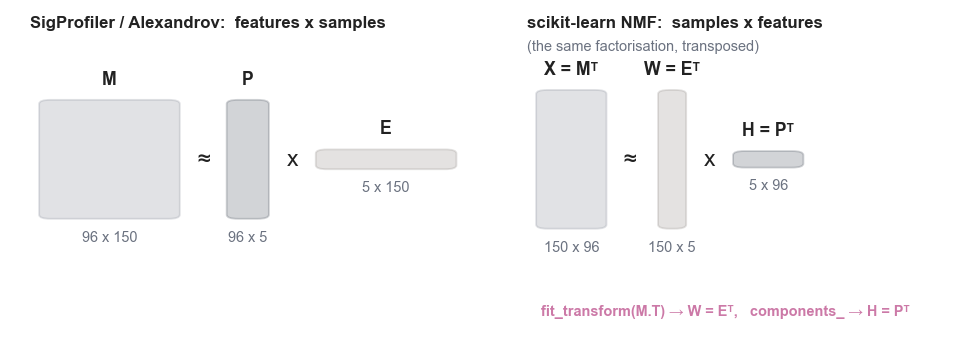

넣은 X = M.T : (150, 96) → W : (150, 5)  components_ : (5, 96)
M.T 를 넣고 components_ 를 P 로: [1.    0.999 0.944 0.998 0.988]
M 을 넣고 W 를 P 로          : [1.    1.    0.95  0.998 0.995]


In [10]:
def draw_orientation(n=150, k=5):
    fig, ax = plt.subplots(figsize=(11, 3.9)); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_axis_off()
    def blk(x, yc, w, h, name, shape, color):
        ax.add_patch(FancyBboxPatch((x, yc - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.012",
                                    facecolor=color, alpha=0.2, edgecolor=color, linewidth=1.2))
        ax.text(x + w / 2, yc + h / 2 + 0.035, name, ha="center", va="bottom", fontsize=11.5, fontweight="semibold", color=COL["ink"])
        ax.text(x + w / 2, yc - h / 2 - 0.035, shape, ha="center", va="top", fontsize=9.5, color=COL["muted"])
    def op(x, yc, t):
        ax.text(x, yc, t, ha="center", va="center", fontsize=15, color=COL["ink"])
    yc = 0.55
    ax.text(0.02, 0.95, "SigProfiler / Alexandrov:  features x samples", fontsize=11, fontweight="semibold", color=COL["ink"])
    blk(0.03, yc, 0.15, 0.36, "M", f"96 x {n}", COL["data"]); op(0.205, yc, "≈")
    blk(0.23, yc, 0.045, 0.36, "P", f"96 x {k}", COL["facP"]); op(0.30, yc, "x")
    blk(0.325, yc, 0.15, 0.06, "E", f"{k} x {n}", COL["facE"])
    ax.text(0.55, 0.95, "scikit-learn NMF:  samples x features", fontsize=11, fontweight="semibold", color=COL["ink"])
    note(ax, 0.55, 0.88, "(the same factorisation, transposed)", fontsize=9.5)
    blk(0.56, yc, 0.075, 0.42, "X = Mᵀ", f"{n} x 96", COL["data"]); op(0.66, yc, "≈")
    blk(0.69, yc, 0.03, 0.42, "W = Eᵀ", f"{n} x {k}", COL["facE"]); op(0.745, yc, "x")
    blk(0.77, yc, 0.075, 0.05, "H = Pᵀ", f"{k} x 96", COL["facP"])
    callout(ax, 0.565, 0.09, "fit_transform(M.T) → W = Eᵀ,   components_ → H = Pᵀ", fontsize=9.5, va="center")
    plt.show()

draw_orientation()
model = NMF(n_components=5, beta_loss="kullback-leibler", solver="mu", init="random", max_iter=50, random_state=0)
W = model.fit_transform(M.T)
print("넣은 X = M.T :", M.T.shape, "→ W :", W.shape, " components_ :", model.components_.shape)
assert W.shape == (M.shape[1], 5) and model.components_.shape == (5, 96)

# 두 방향 비교: M.T 를 넣고 components_ 를 P 로 읽기 vs M 을 그대로 넣고 W 를 P 로 읽기
def p_from(Pcols):
    P = Pcols / Pcols.sum(axis=0); return match(P_true.values, P)[1]
m1 = NMF(n_components=5, beta_loss="kullback-leibler", solver="mu", init="random", max_iter=1500, tol=1e-6, random_state=0)
m1.fit_transform(M.T); cos_T = p_from(m1.components_.T)
m2 = NMF(n_components=5, beta_loss="kullback-leibler", solver="mu", init="random", max_iter=1500, tol=1e-6, random_state=0)
W2 = m2.fit_transform(M); cos_noT = p_from(W2)
print("M.T 를 넣고 components_ 를 P 로:", cos_T.round(3))
print("M 을 넣고 W 를 P 로          :", cos_noT.round(3))
assert cos_T.min() > 0.85 and cos_noT.min() > 0.85

**그림에서 볼 것**: 왼쪽(SigProfiler)과 오른쪽(scikit-learn)은 같은 분해를 전치(transpose)해서 쓴 것입니다. scikit-learn 문서는 X 를 `(n_samples, n_features)`, `fit_transform` 이 돌려주는 W 를 `(n_samples, n_components)`, `components_` 를 `(n_components, n_features)` 로 적습니다 [6].

출력의 두 줄: 어느 방향으로 넣어도 P 를 거의 같게 찾습니다(조금 다른 것은 시작점이 달라서입니다). 방향이 바뀌면 **어느 행렬을 P 로 읽어야 하는지**만 바뀝니다.

이 노트북의 `nmf_kl()` 은 이 전치를 안에서 처리하고, P 를 열 합 1 로 맞춘 뒤 그만큼 E 를 키워 "P 는 확률, E 는 변이 수"가 되게 돌려줍니다.

## 6. 무엇을 최소로 하나: 개수 데이터에는 KL 발산

**한 줄 정의**: M 과 P × E 의 차이를 재는 잣대로, 개수 데이터에는 제곱 오차 대신 **KL 발산(generalized Kullback–Leibler divergence)** 을 흔히 씁니다. SigProfilerExtractor 도 KL 을 최소로 하는 곱셈 갱신 NMF 를 씁니다 [4].

**왜 필요한가**: 변이 개수는 포아송처럼 흔들립니다. 개수가 큰 칸은 절대 흔들림도 커서, 제곱 오차는 큰 칸에 끌려갑니다. KL 은 포아송 우도와 같은 것을 잽니다(아래 첫째 확인). 그리고 데이터가 모형에 가까울 때 KL 은 대략 $\sum (m-\mu)^2 / (2\mu)$ 와 같아서, 칸마다 차이를 그 칸의 기댓값 μ(포아송 분산)로 나눠 무게를 줍니다(아래 둘째 확인, 이 노트북의 근사 계산).

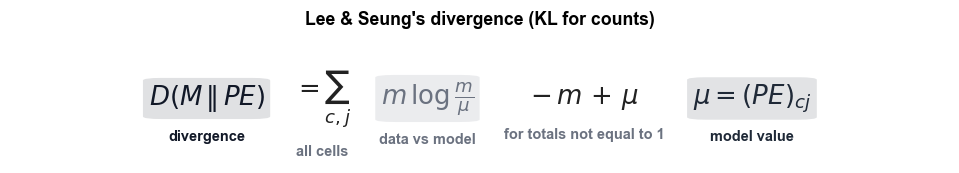

In [11]:
show_formula([
    (r"$D(M\,\|\,PE)$", COL["metric"], "divergence"),
    (r"$=\sum_{c,j}$", None, "all cells"),
    (r"$m\,\log\frac{m}{\mu}$", COL["data"], "data vs model"),
    (r"$-\,m\,+\,\mu$", None, "for totals not equal to 1"),
    (r"$\mu = (PE)_{cj}$", COL["facP"], "model value"),
], title="Lee & Seung's divergence (KL for counts)")

| 기호 | 소리 내어 읽기 | 뜻 |
|---|---|---|
| $D(M\,\|\,PE)$ | "M 에서 PE 까지의 발산" | 데이터가 모형에서 얼마나 떨어졌나. 0 이면 같다 |
| $m$, $\mu$ | "엠, 뮤" | 한 칸의 관측 개수, 모형 값 |
| $m \log \frac{m}{\mu} - m + \mu$ | | 칸 하나의 몫. 늘 0 이상, $m = \mu$ 일 때만 0 |
| $-m + \mu$ | | 합이 1 이 아닌 개수끼리도 발산이 되게 하는 보정 항 |

Lee 와 Seung 은 이 식을 정의하고, A 와 B 의 합이 1 이면 Kullback–Leibler 발산이 된다고 적었습니다(식 3) [3]. 즉 $-m + \mu$ 는 합이 1 이 아닌 일반 개수에서 쓰려고 붙인 항입니다.

**이 노트북에서 유도**: 포아송 로그 우도는 $\sum (m \log \mu - \mu - \log m!)$ 입니다. 여기에 $m\log m - m$ 처럼 모형과 상관없는 항을 더하고 부호를 바꾸면 위 D 가 됩니다. 그래서 **D 를 줄이는 것 = 포아송 우도를 키우는 것**입니다. 숫자로 확인합니다.

In [12]:
from scipy.special import gammaln
def kl_div(Mx, Mu):
    m, mu = Mx.ravel(), Mu.ravel()
    return np.sum(np.where(m > 0, m * np.log(np.where(m > 0, m, 1) / mu), 0) - m + mu)
def pois_loglik(Mx, Mu):
    return np.sum(Mx * np.log(Mu) - Mu - gammaln(Mx + 1))
const = np.sum(np.where(M > 0, M * np.log(np.where(M > 0, M, 1)), 0) - M - gammaln(M + 1))
for name, Mu in [("true P x E", P_true.values @ E_true.values), ("worse model (flat)", np.full_like(M, M.mean()))]:
    d, ll = kl_div(M, Mu), pois_loglik(M, Mu)
    print(f"{name:20s} D = {d:12.1f}   Poisson loglik = {ll:12.1f}   D + loglik = {d + ll:12.1f}")
    assert np.isclose(d + ll, const)          # 두 모형에서 합이 같은 상수 → D 와 -loglik 은 상수만큼 차이

# 둘째 확인: 모형 가까이에서 D ≈ Σ (m − μ)² / (2μ)  → 칸마다 차이를 μ 로 나눈 무게
Mu = P_true.values @ E_true.values
chi_half = np.sum((M - Mu) ** 2 / (2 * Mu))
print(f"D = {kl_div(M, Mu):.1f}   vs   Σ (m - μ)² / (2μ) = {chi_half:.1f}")
assert abs(kl_div(M, Mu) / chi_half - 1) < 0.1

true P x E           D =       7373.4   Poisson loglik =     -40430.4   D + loglik =     -33057.0
worse model (flat)   D =     567264.6   Poisson loglik =    -600321.6   D + loglik =     -33057.0
D = 7373.4   vs   Σ (m - μ)² / (2μ) = 7277.5


**표에서 볼 것**
- 두 모형에서 "D + 로그 우도"가 같은 숫자입니다. 즉 D 가 작은 모형이 곧 우도가 큰 모형입니다.
- 정답 모형 가까이에서 D 는 $\sum (m-\mu)^2/(2\mu)$ 와 거의 같습니다. 기댓값이 100 인 칸에서 10 개 차이와, 기댓값이 1 인 칸에서 1 개 차이가 비슷한 무게가 됩니다. 제곱 오차는 앞쪽을 100 배 무겁게 봅니다.
- 곱셈 갱신이 D 를 줄이는 원리는 N2 에서 봅니다(Lee & Seung 의 정리 2 [3]).

## 7. de novo 추출: k 를 모를 때

**한 줄 정의**: 정답 signature 를 모른다고 치고 M 만 보고 P 와 E 를 함께 찾는 것이 de novo 추출입니다. 먼저 몇 개(k)로 나눌지 정해야 합니다.

**왜 필요한가**: k 가 너무 작으면 서로 다른 과정이 한 signature 에 섞이고, 너무 크면 하나가 둘로 쪼개지거나 잡음이 signature 가 됩니다.

여기서는 SigProfilerExtractor 의 생각을 줄여 따라 합니다 [4]. k 마다 (1) M 을 포아송으로 다시 뽑아(재표집) 여러 번 분해하고, (2) 매번 나온 signature 를 짝 맞춰 같은 무리로 묶고, (3) 무리가 얼마나 또렷한지(silhouette)를 안정성으로, 군집 중심으로 다시 맞춘 오차를 정확도로 봅니다. k 고르기의 원리는 N3 에서 자세히 봅니다.

In [13]:
t0 = time.perf_counter()
scan = stability_scan(M, ks=range(2, 9), reps=8, seed=1)
k_hat = choose_k(scan)
print(f"계산 시간 {time.perf_counter() - t0:.1f}초")
print(pd.DataFrame({k: dict(avg_stability=round(v["stab"], 3), min_stability=round(v["stab_min"], 3),
                            rel_error=round(v["err"], 4)) for k, v in scan.items()}).T)
print("고른 k =", k_hat, "  (SigProfilerExtractor 식 Wilcoxon 규칙으로는", choose_k_wilcoxon(scan, M), ")")
assert k_hat == 5

계산 시간 4.7초
   avg_stability  min_stability  rel_error
2          0.834          0.725     0.3628
3          0.937          0.869     0.2357
4          0.996          0.992     0.1073
5          0.988          0.954     0.0548
6          0.716         -0.598     0.0544
7          0.491         -0.669     0.0539
8          0.392         -0.659     0.0550
고른 k = 5   (SigProfilerExtractor 식 Wilcoxon 규칙으로는 5 )


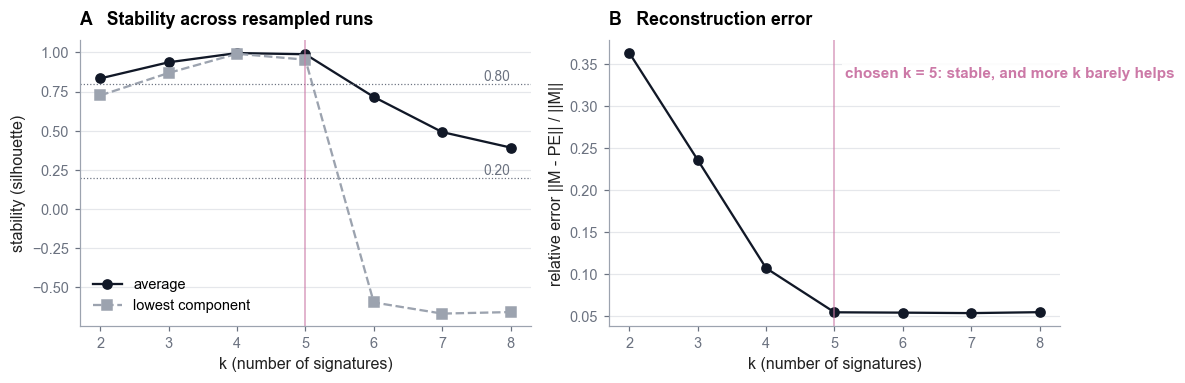

In [14]:
def draw_k_scan(scan, k_hat, title="Choosing k: stable and accurate"):
    ks = sorted(scan); fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].plot(ks, [scan[k]["stab"] for k in ks], "-o", color=COL["metric"], label="average")
    ax[0].plot(ks, [scan[k]["stab_min"] for k in ks], "--s", color=COL["metric2"], label="lowest component")
    ax[0].axhline(0.8, color=COL["muted"], lw=0.8, ls=":"); ax[0].axhline(0.2, color=COL["muted"], lw=0.8, ls=":")
    note(ax[0], ks[-1], 0.82, "0.80", ha="right"); note(ax[0], ks[-1], 0.22, "0.20", ha="right")
    lo = min(-0.1, min(scan[k]["stab_min"] for k in ks) - 0.08); ax[0].set_ylim(lo, 1.08); ax[0].set_xlabel("k (number of signatures)"); ax[0].set_ylabel("stability (silhouette)")
    ax[0].legend(loc="lower left"); panel(ax[0], "A", "Stability across resampled runs"); ygrid(ax[0])
    ax[1].plot(ks, [scan[k]["err"] for k in ks], "-o", color=COL["metric"])
    ax[1].set_xlabel("k (number of signatures)"); ax[1].set_ylabel("relative error ||M - PE|| / ||M||")
    panel(ax[1], "B", "Reconstruction error"); ygrid(ax[1])
    for a in ax:
        a.axvline(k_hat, color=COL["highlight"], lw=1.2, alpha=0.6)
    callout(ax[1], k_hat + 0.15, max(scan[k]["err"] for k in ks) * 0.92, f"chosen k = {k_hat}: stable, and more k barely helps")
    plt.tight_layout(); plt.show()

draw_k_scan(scan, k_hat)

**그림에서 볼 것**
- A: k = 5 까지는 매번 거의 같은 signature 가 나와 안정성이 높습니다. k 가 정답(5)을 넘으면 남는 성분이 매번 다르게 쪼개져 가장 낮은 성분의 안정성이 떨어집니다.
- B: 오차는 k 를 늘릴수록 줄지만, 5 를 넘으면 거의 줄지 않습니다. 남는 성분이 잡음을 맞추는 데만 쓰이기 때문입니다.
- 이 노트북의 규칙: 안정한 k(평균 ≥ 0.80, 가장 낮은 성분 ≥ 0.20)[4] 가운데, k 를 하나 늘려 오차가 1% 포인트 넘게 줄어드는 동안만 올라갑니다. SigProfilerExtractor 의 실제 선택 규칙은 다릅니다(11절에서 나란히 비교).

**직접 바꿔 보기**: `reps=8` 을 3 으로 줄이면 안정성 곡선이 들쭉날쭉해집니다. 재표집 횟수가 적으면 안정성 추정 자체가 흔들립니다.

## 8. 뽑은 signature 를 정답과 맞추기: 코사인 유사도와 짝 맞추기

**한 줄 정의**: 두 96칸 분포가 얼마나 닮았는지를 두 벡터 사이 각도의 코사인으로 잽니다. 1 이면 모양이 같습니다. 여러 개를 한꺼번에 맞출 때는 "코사인 합이 가장 큰 1:1 짝"을 찾습니다.

**왜 필요한가**: NMF 는 성분의 순서를 정하지 않습니다(N2 의 모호함). 뽑은 첫째 성분이 정답 첫째와 같다는 보장이 없어서, 짝을 먼저 맞춰야 비교할 수 있습니다. SigProfilerExtractor 는 반복 결과끼리 맞출 때 Hungarian 알고리즘을 씁니다 [4]. 이 노트북은 같은 문제(할당 문제)를 푸는 SciPy `linear_sum_assignment` 를 씁니다 [9].

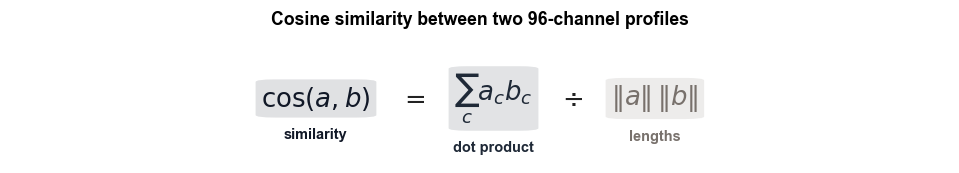

In [15]:
show_formula([
    (r"$\cos(a,b)$", COL["metric"], "similarity"),
    (r"$=$", None, None),
    (r"$\sum_c a_c b_c$", COL["facP"], "dot product"),
    (r"$\div$", None, None),
    (r"$\|a\|\,\|b\|$", COL["facE"], "lengths"),
], title="Cosine similarity between two 96-channel profiles")

| 기호 | 소리 내어 읽기 | 뜻 |
|---|---|---|
| $\sum_c a_c b_c$ | "칸마다 a 와 b 를 곱해 더하기" | 내적. 두 분포가 같은 칸에서 함께 높을수록 커진다 |
| $\|a\|$ | "a 의 길이" | $\sqrt{\sum_c a_c^2}$. 나누면 전체 크기(변이 수)와 상관없이 모양만 비교된다 |
| $\cos(a,b)$ | "a 와 b 의 코사인" | 0~1(음수가 없는 분포끼리). 1 이면 모양이 같다 |

**숫자 넣기**: 칸이 4개뿐인 장난감 분포 a = (0.5, 0.3, 0.2, 0), b = (0.4, 0.4, 0.1, 0.1) 이면
내적 = 0.5×0.4 + 0.3×0.4 + 0.2×0.1 + 0×0.1 = 0.34, ‖a‖ = √0.38 = 0.616, ‖b‖ = √0.34 = 0.583, 코사인 = 0.34 / (0.616 × 0.583) = 0.946.

**얼마면 닮은 것인가**: 음수가 없는 벡터끼리는 아무렇게나 뽑아도 코사인이 평균 0.75 쯤 나옵니다 [4]. 그래서 0.8 은 "닮았다"고 하기에 약하고, SigProfilerExtractor 논문은 0.80 아래는 우연일 수 있다고 보고 그 위만 비교했습니다 [4]. 이 노트북은 0.9 이상을 "같은 signature"로 읽습니다(이 노트북의 기준).

In [16]:
a = np.array([0.5, 0.3, 0.2, 0.0]); b = np.array([0.4, 0.4, 0.1, 0.1])
print("cos(a, b) =", round(float(cos_matrix(a[:, None], b[:, None])[0, 0]), 3))
assert np.isclose(cos_matrix(a[:, None], b[:, None])[0, 0], 0.34 / (np.sqrt(0.38) * np.sqrt(0.34)))
assert np.isclose(cos_matrix(a[:, None], (10 * a)[:, None])[0, 0], 1.0)      # 크기만 다르면 1

cos(a, b) = 0.946


짝지은 코사인: {'SigA CpG C>T (clock-like)': 1.0, 'SigB APOBEC-like (TCW)': 1.0, 'SigC flat': 0.945, 'SigD T>C-rich': 0.999, 'SigE C>A-rich': 0.998}
SigC 행, 짝 아닌 칸: [0.25 0.31 0.46 0.46]   new 3 열, 짝 아닌 칸: [0.34 0.18 0.3  0.22]   그 밖의 짝 아닌 칸 최댓값: 0.1


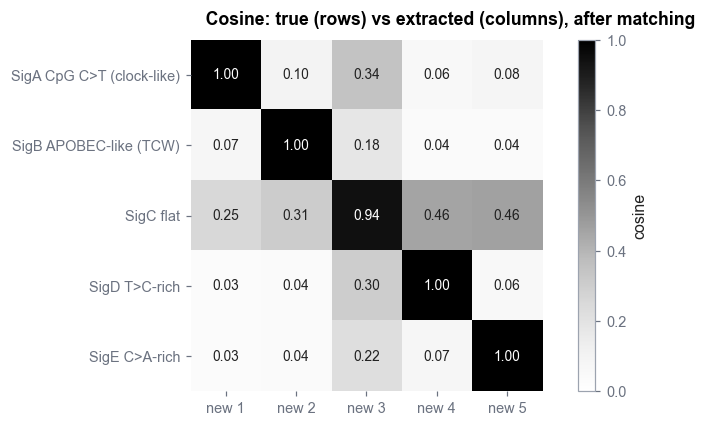

In [17]:
P_hat, E_hat = scan[k_hat]["P"], scan[k_hat]["E"]
order, cosv = match(P_true.values, P_hat)
P_hat, E_hat = P_hat[:, order], E_hat[order]
C = cos_matrix(P_true.values, P_hat)
print("짝지은 코사인:", dict(zip(P_true.columns, cosv.round(3))))
assert cosv.min() > 0.90
off = ~np.eye(len(cosv), dtype=bool)
print("SigC 행, 짝 아닌 칸:", C[2][off[2]].round(2), "  new 3 열, 짝 아닌 칸:", C[:, 2][off[:, 2]].round(2),
      "  그 밖의 짝 아닌 칸 최댓값:", round(float(np.delete(np.delete(C, 2, 0), 2, 1)[~np.eye(4, dtype=bool)].max()), 2))

def draw_cos_heatmap(C, rows, cols, title):
    fig, ax = plt.subplots(figsize=(7.2, 4.0))
    im = ax.imshow(C, cmap="Greys", vmin=0, vmax=1)
    for i in range(C.shape[0]):
        for j in range(C.shape[1]):
            ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=9, color="white" if C[i, j] > 0.6 else COL["ink"])
    ax.set_xticks(range(C.shape[1]), cols, rotation=0); ax.set_yticks(range(C.shape[0]), rows)
    ax.spines[:].set_visible(False); plt.colorbar(im, ax=ax, fraction=0.04, label="cosine")
    panel(ax, "", title); plt.tight_layout(); plt.show()

draw_cos_heatmap(C, list(P_true.columns), [f"new {i + 1}" for i in range(k_hat)], "Cosine: true (rows) vs extracted (columns), after matching")

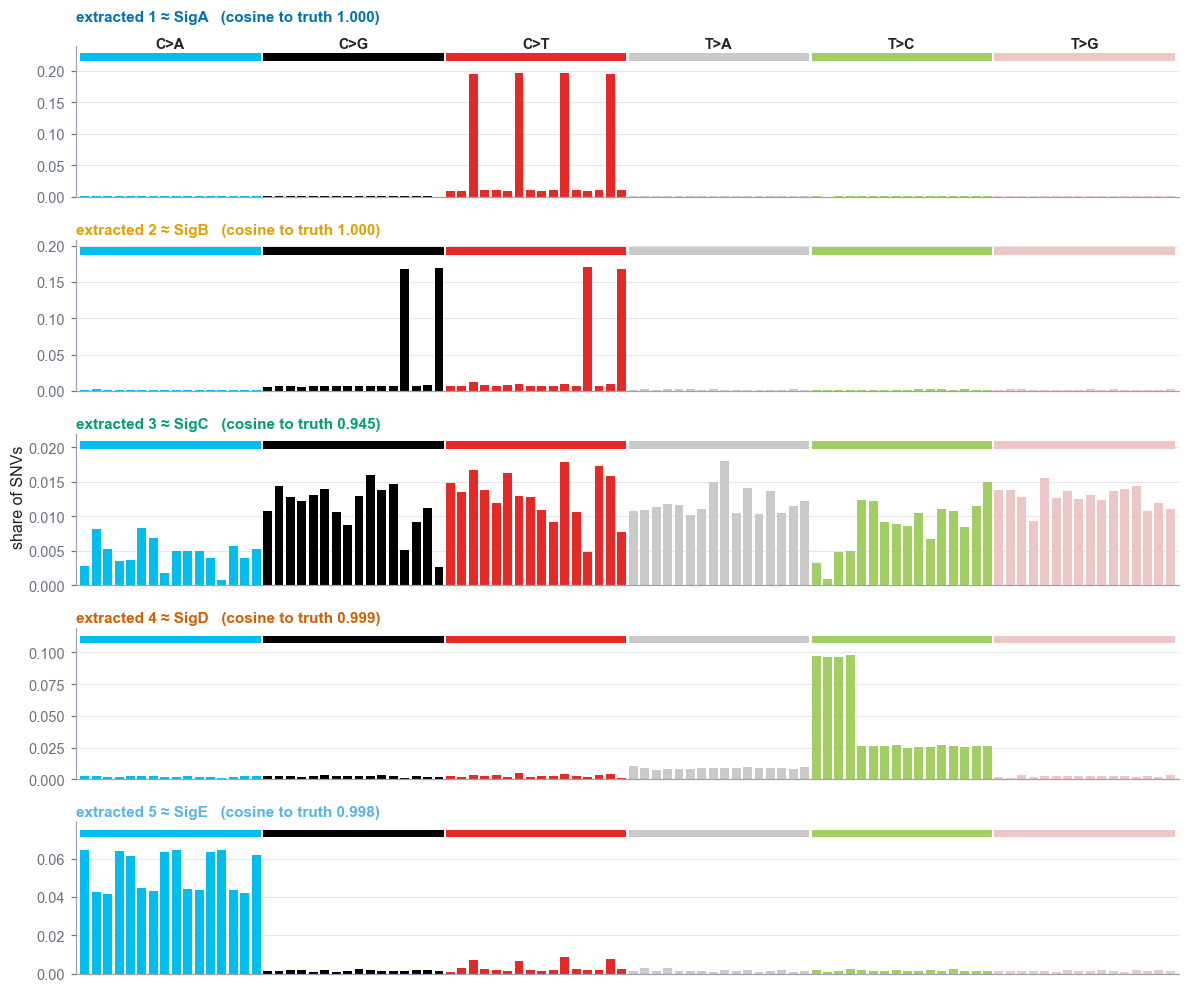

In [18]:
draw_signatures(pd.DataFrame(P_hat, index=CHANNELS, columns=[f"extracted {i + 1} ≈ {n.split()[0]}" for i, n in enumerate(P_true.columns)]),
                cos_vals=cosv)

**그림에서 볼 것**
- 히트맵의 대각선이 진하고(코사인이 1 에 가깝고) 나머지는 대부분 옅습니다. 짝을 맞춘 뒤의 모습입니다.
- 예외는 평평한 SigC 쪽입니다. SigC 행은 짝이 아닌 칸도 0.25~0.46 이고, new 3 열도 짝이 아닌 칸이 0.18~0.34 으로 중간 회색입니다(그 밖의 짝 아닌 칸은 모두 0.10 이하). 평평한 분포는 어떤 분포와도 어느 정도 겹치기 때문입니다(모든 칸에 조금씩 값이 있으니 내적이 0 이 되지 않습니다).
- 가장 낮은 짝도 보통 SigC 입니다. 평평한 모양은 다른 signature 의 바닥과 구별이 덜 되어 조금씩 섞입니다.
- 아래 96칸 그림은 위의 정답 그림과 모양이 거의 같습니다. 다만 extracted 3(SigC)은 하늘색 C>A 칸과 초록 T>C 의 앞 네 칸(앞 염기 A)이 정답보다 낮습니다. 평평한 SigC 의 그 몫을 SigE(C>A)와 SigD(A[T>C]N)가 가져간 것입니다.

## 9. 이미 아는 signature 가 있으면: NNLS 로 노출량만 다시 구하기(refit, assignment)

**한 줄 정의**: P 를 고정하고 표본마다 "m ≈ P a, a ≥ 0"을 푸는 것입니다(음수 없는 최소제곱, NNLS) [8]. de novo 처럼 P 까지 찾지 않습니다.

**왜 필요한가**: 표본 수가 적거나 변이가 적으면 de novo 로 P 를 믿을 만하게 뽑기 어렵습니다. 이미 잘 알려진 signature(예: COSMIC 참조)가 있으면 노출량만 구하는 편이 안정적입니다. SigProfilerAssignment 가 이 일을 합니다 [5].

아래에서 세 가지 노출량을 정답과 비교합니다: (가) de novo 로 뽑은 P 로 NNLS 한 E(7절의 `stability_scan` 이 이렇게 구합니다), (나) 정답 P 로 NNLS 한 E, (다) 정답 P 에서 평평한 SigC 를 뺀 4개로 NNLS 한 E(빠진 signature 가 있을 때).

In [19]:
E_refit = refit_nnls(M, P_true.values)
E_miss = refit_nnls(M, P_true.values[:, [0, 1, 3, 4]])
def frac(E):
    return E / E.sum(axis=0, keepdims=True)
F_true = frac(E_true.values)
err = pd.DataFrame({
    "NNLS, de novo P":        np.abs(frac(E_hat) - F_true).sum(0) / 2,
    "NNLS, true P":           np.abs(frac(E_refit) - F_true).sum(0) / 2,
    "NNLS, SigC missing":     np.abs(np.insert(frac(E_miss), 2, 0, axis=0) - F_true).sum(0) / 2,
}, index=M_df.columns)
print("표본마다 '노출 비율이 정답과 얼마나 다른가'(0 = 같음, 1 = 완전히 다름)의 중앙값:")
print(err.median().round(3))
assert err.median()["NNLS, true P"] < err.median()["NNLS, de novo P"] < err.median()["NNLS, SigC missing"]

표본마다 '노출 비율이 정답과 얼마나 다른가'(0 = 같음, 1 = 완전히 다름)의 중앙값:
NNLS, de novo P       0.098
NNLS, true P          0.016
NNLS, SigC missing    0.320
dtype: float64


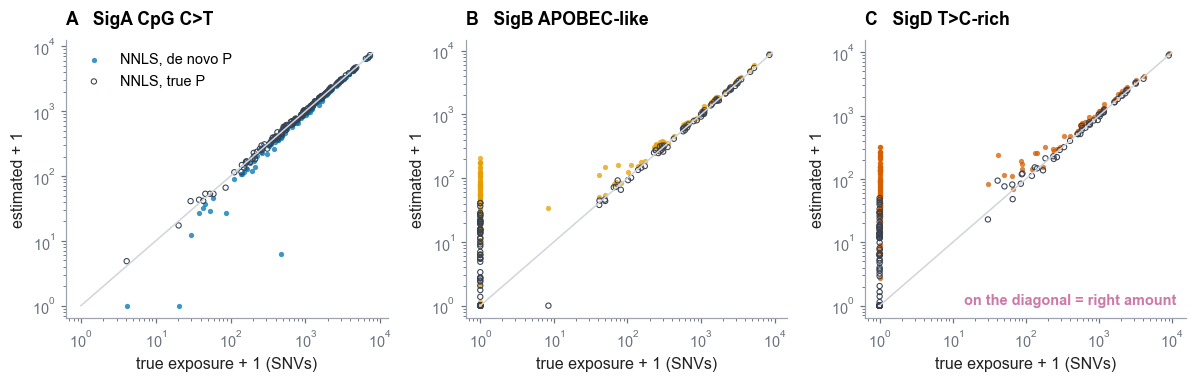

In [20]:
def draw_exposure_compare(E_true, E_hat, E_refit, names):
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=False)
    for i, ax in enumerate(axes):
        s = [0, 1, 3][i]
        t = E_true[s]; ax.plot([1, t.max() * 1.1], [1, t.max() * 1.1], color=COL["none"], lw=1)
        ax.scatter(t + 1, E_hat[s] + 1, s=12, color=COMP[s], alpha=0.75, linewidths=0, label="NNLS, de novo P")
        ax.scatter(t + 1, E_refit[s] + 1, s=12, facecolors="none", edgecolors=COL["true"], linewidths=0.7, label="NNLS, true P")
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel("true exposure + 1 (SNVs)"); ax.set_ylabel("estimated + 1")
        panel(ax, "ABC"[i], names[s].split(" (")[0])
        if i == 0:
            ax.legend(loc="upper left")
    callout(axes[2], 0.97, 0.05, "on the diagonal = right amount", transform=axes[2].transAxes, fontsize=9.5, ha="right")
    plt.tight_layout(); plt.show()

draw_exposure_compare(E_true.values, E_hat, E_refit, list(P_true.columns))

**그림에서 볼 것**
- 점이 대각선 위에 있으면 노출량을 맞게 찾은 것입니다. 색 점(de novo 로 뽑은 P 로 NNLS)과 빈 동그라미(정답 P 로 NNLS)가 대부분 대각선에 붙습니다.
- B·C 의 맨 왼쪽 세로줄은 정답이 0 인 표본입니다. de novo 추정(색 점)은 여기서 수십~수백 개로 뜹니다. 다른 signature, 특히 평평한 SigC 의 몫이 새어 들어온 것입니다. 정답 P 로 NNLS 한 빈 동그라미도 뜨지만 덜합니다.
- 위 표: 정답 P 로 NNLS 한 것이 가장 정확하고, signature 하나가 빠진 채 NNLS 하면 가장 나쁩니다. 빠진 과정의 변이는 다른 signature 에 억지로 나눠 들어갑니다.

> **시퀀싱 데이터에서는** "참조 목록에 없는 과정"이 실제로 있을 수 있습니다. 그래서 큰 코호트는 de novo 로 먼저 뽑아 참조와 맞춰 보고, 참조로 다시 맞춘 뒤의 재구성 코사인이 낮은 표본을 따로 살핍니다. SigProfilerExtractor 도 이 순서입니다: de novo signature 를 COSMIC 조합으로 분해하고(Module 5), 그 결과로 표본마다 노출량을 NNLS 로 다시 구합니다(Module 6) [4].

## 10. 변이가 적은 시료는 왜 흔들리나

**한 줄 정의**: 96칸 개수는 포아송처럼 흔들리고, 칸당 개수가 적을수록 상대적 흔들림(≈ 1/√개수)이 큽니다. 그래서 변이가 수백 개인 시료의 노출 비율은 믿기 어렵습니다.

**숫자로 따라가기**: 같은 비율(SigA 50%, SigB 30%, SigC 20%)을 가진 표본을 변이 수만 바꿔 200번씩 새로 뽑고, 정답 P 로 NNLS 해서 비율 오차를 봅니다.

       n  median_error    q90
0     50         0.129  0.214
1    100         0.093  0.164
2    200         0.067  0.117
3    500         0.037  0.073
4   1000         0.029  0.050
5   3000         0.017  0.032
6  10000         0.009  0.017
7  30000         0.005  0.009


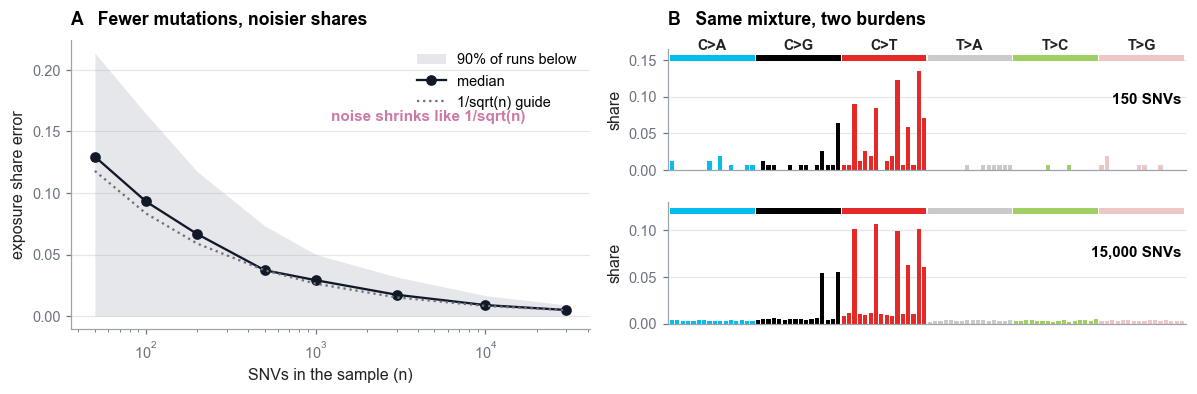

In [21]:
def burden_experiment(P, fr=(0.5, 0.3, 0.2, 0, 0), ns=(50, 100, 200, 500, 1000, 3000, 10000, 30000), reps=200, seed=3):
    rng = np.random.default_rng(seed); fr = np.array(fr); rows = []
    for n in ns:
        e = []
        for _ in range(reps):
            m = rng.poisson(P @ (fr * n)); a = nnls(P, m)[0]
            e.append(np.abs(a / a.sum() - fr).sum() / 2)
        rows.append(dict(n=n, median_error=np.median(e), q90=np.quantile(e, 0.9)))
    return pd.DataFrame(rows)

be = burden_experiment(P_true.values)
print(be.round(3))
assert be.median_error.iloc[0] > 3 * be.median_error.iloc[-1]

def draw_burden(be):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
    ax[0].fill_between(be.n, 0, be.q90, color=COL["metric2"], alpha=0.25, lw=0, label="90% of runs below")
    ax[0].plot(be.n, be.median_error, "-o", color=COL["metric"], label="median")
    guide = be.median_error.iloc[3] * np.sqrt(be.n.iloc[3] / be.n)
    ax[0].plot(be.n, guide, ":", color=COL["muted"], label="1/sqrt(n) guide")
    ax[0].set_xscale("log"); ax[0].set_xlabel("SNVs in the sample (n)"); ax[0].set_ylabel("exposure share error")
    ax[0].legend(loc="upper right"); panel(ax[0], "A", "Fewer mutations, noisier shares"); ygrid(ax[0])
    callout(ax[0], 0.50, 0.72, "noise shrinks like 1/sqrt(n)", transform=ax[0].transAxes)
    rng = np.random.default_rng(5); fr = np.array([0.5, 0.3, 0.2, 0, 0])
    small = rng.poisson(P_true.values @ (fr * 150)); big = rng.poisson(P_true.values @ (fr * 15000))
    axb = ax[1]; axb.set_axis_off()
    in1 = axb.inset_axes([0, 0.55, 1, 0.42]); in2 = axb.inset_axes([0, 0.02, 1, 0.42])
    plot96(in1, small / small.sum(), ylabel="share"); plot96(in2, big / big.sum(), ylabel="share", top_labels=False)
    in1.text(0.99, 0.55, "150 SNVs", transform=in1.transAxes, ha="right", fontsize=10, fontweight="semibold")
    in2.text(0.99, 0.55, "15,000 SNVs", transform=in2.transAxes, ha="right", fontsize=10, fontweight="semibold")
    panel(axb, "B", "Same mixture, two burdens")
    plt.tight_layout(); plt.show()

draw_burden(be)

**그림에서 볼 것**
- A: 변이 50개일 때 비율 오차 중앙값이 수만 개일 때보다 훨씬 큽니다. 점선(1/√n)과 비슷하게 줄어듭니다.
- 위 표에서 변이 500개 줄을 보면 중앙값 0.037, 90% 지점 0.073 입니다. 노출 비율이 대개 4% 포인트 안쪽으로 맞지만, 열 번에 한 번은 7% 포인트 넘게 어긋난다는 뜻입니다.
- 이 숫자는 좋은 조건에서의 값입니다. signature 가 5개뿐이고 정답 P 를 알고 있습니다. 실제 참조 목록(COSMIC)은 SBS 만 수십 개이고 서로 닮은 것(평평한 SBS3·SBS5·SBS40 등)이 많아, 같은 변이 수에서도 더 흔들립니다.
- B: 같은 혼합이라도 150개짜리 96칸 그림은 막대가 듬성듬성하고 들쭉날쭉해, 모양을 읽기 어렵습니다. 15,000개짜리는 매끈합니다.

> **시퀀싱 데이터에서는** 변이가 적은 종양(예: 낮은 purity 로 변이를 덜 부른 시료, 엑솜·패널)에서는 signature 비율의 불확실성이 큽니다. 비교할 때 변이 수를 함께 적고, 아주 적은 시료는 따로 표시합니다.

## 11. 실제 도구는 무엇을 더 하나: SigProfilerExtractor 와 SigProfilerAssignment

논문에서 확인한 만큼만 적습니다.

처음 나오는 이름 풀이:
- **GMM 정규화**: 가우스 혼합 모형(Gaussian mixture model, 종 모양 분포 여러 개를 섞은 모형)으로 표본들의 총 변이 수를 무리 지어, 유난히 큰 무리의 표본을 줄이는 방법.
- **NNDSVD**: 특이값 분해(SVD, 행렬을 회전·늘이기로 쪼개는 방법)에서 음수를 지운 값으로 NMF 의 시작점을 정하는 방법. 무작위 시작 대신 씁니다.
- **Itakura–Saito**: KL·Frobenius 처럼 "M 과 PE 가 얼마나 다른가"를 재는 또 하나의 기준. 비율 m/μ 만 보아서 큰 값과 작은 값을 똑같이 대합니다.
- **forward stagewise**: signature 를 한 번에 다 넣지 않고, 하나씩 넣고 빼며 조금씩 목록을 키우는 선택 방식.
- **Lawson–Hanson**: 음수 없는 최소제곱(NNLS)을 푸는 대표 알고리즘(Lawson·Hanson 의 책 *Solving Least Squares Problems*, 1974). 음수가 되려는 값을 0 에 묶어 두고 나머지로 최소제곱을 푸는 일을 되풀이합니다(활성 집합법). 이 노트북이 쓰는 SciPy 1.11 의 `nnls` 도 이 책의 코드를 씁니다.

**SigProfilerExtractor(de novo 추출)** [4]
- k 마다 기본 **100번** 분해합니다. 매번 M 을 먼저 **포아송 재표집하고 정규화**(기본 GMM)한 뒤, **KL 발산을 최소로 하는 곱셈 갱신 NMF** 로 나눕니다. 기본 시작점은 **무작위**, 기본 기준은 **KL** 이고, 분해 한 번에 **최소 10,000번, 최대 1,000,000번** 갱신하며 수렴 허용치는 **10⁻¹⁵** 입니다.
- 100개 결과를 **Hungarian 알고리즘으로 짝 맞추는 분할 군집**으로 묶고, 군집 중심을 그 k 의 합의(consensus) signature 로 냅니다. 군집이 얼마나 또렷한지를 **silhouette** 로 잽니다.
- WGS 에서는 signature 들의 **평균 안정성이 0.80 보다 크고, 0.20 아래인 것이 없으면** 안정한 해로 봅니다(엑솜은 0.70, 0.10).
- 뽑은 de novo signature 를 **COSMIC 참조 signature 의 조합으로 분해**(Module 5)하고, 분해되지 않으면 새 signature 로 보고합니다. 분해는 SBS1·SBS5 로 시작해, 하나 더했을 때 L2 오차가 **5% 넘게** 줄면 넣고, 하나 뺐을 때 **1% 미만**으로만 늘면 빼기를 되풀이합니다. 표본별 노출량은 Module 6 이 같은 더하기·빼기로 NNLS 해서 구합니다.
- 정규화는 GMM·100X·log2·안 함 중에서, 곱셈 갱신은 KL·Euclidean·Itakura–Saito 중에서, 시작점은 무작위·NNDSVD 중에서 고를 수 있습니다.

**k 고르기 규칙 두 가지를 나란히**

| | 이 노트북(`choose_k`) | SigProfilerExtractor, WGS(`choose_k_wilcoxon`) [4] |
|---|---|---|
| 후보 | 안정한 k(평균 ≥ 0.80, 가장 낮은 성분 ≥ 0.20) | 같음 |
| 시작점 | 가장 작은 안정한 k | 가장 큰 안정한 k |
| 움직이는 방향 | 위로: k 를 하나 늘려 전체 상대 오차가 1% 포인트 넘게 줄면 올라감 | 아래로: 표본별 재구성 오차를 가장 큰 k 의 것과 Wilcoxon 순위합 검정으로 비교, p ≥ 0.05 인 동안 내려감 |
| 멈춤 | 오차가 1% 포인트 이하로만 줄 때 | p < 0.05 가 처음 나올 때(가장 큰 k 보다 확실히 못 맞추기 시작할 때) |
| 엑솜 | 같음 | 검정을 하지 않고 가장 큰 안정한 k 를 고름(변이가 적어 민감도를 우선) |

7절 표 아래에 두 규칙의 답을 함께 찍었습니다. 장난감에서는 k ≤ 5 만 안정하므로 두 규칙 모두 후보 안에서 고릅니다. 내 데이터처럼 안정한 k 가 여러 개이면 두 답이 다를 수 있습니다. `choose_k_wilcoxon` 의 표본별 오차 식(‖m − Pe‖ / ‖m‖)은 논문이 적지 않아 이 노트북이 정한 것입니다.

**SigProfilerAssignment(아는 signature 로 노출량 구하기)** [5]
- forward stagewise 선택 단계와 Lawson–Hanson NNLS 를 씁니다. 실제 알고리즘은 모든 signature 로 NNLS 한 뒤, 하나씩 빼 보고(오차가 0.01 이하로만 늘면 뺌) 더해 보기를(오차가 0.05 이상 줄면 더함) 되풀이합니다. 오차는 제곱한 상대 오차입니다.

**이 노트북과 다른 점**
- 반복이 100번이 아니라 8번이고, 군집은 "첫 결과에 맞춰 짝 맞추기"를 3번 되풀이한 단순한 방식입니다(실제 도구는 silhouette 가 10⁻¹² 안으로 수렴할 때까지 되풀이 [4]).
- 분해 한 번에 최대 1,200번(장난감)·3,000번(12절) 갱신하고 허용치는 10⁻⁶ 입니다. 실제 도구의 최소 10,000번·10⁻¹⁵ 보다 훨씬 일찍 멈춥니다. 시작점(무작위)과 기준(KL)은 같습니다.
- 장난감(7절)은 재표집 뒤 정규화를 하지 않습니다. 12절의 내 데이터는 매 반복마다 재표집 → 100X 정규화 순서로 합니다. SigProfilerExtractor 는 이 정규화를 "초변이(hypermutator) 표본이 분해를 기울이지 않게" 하려고 하고, 기본값은 GMM 입니다. 100X 는 어떤 표본도 총 변이 수가 채널 수의 100배를 넘지 않게 합니다 [4]. 노출량(E)은 두 경우 모두 정규화하지 않은 원래 M 으로 NNLS 해서 구합니다.
- COSMIC 분해(Module 5)를 하지 않습니다. 장난감은 정답과 코사인으로 맞추고, 12절은 COSMIC 하나하나와의 코사인과 "NNLS 로 섞은 상위 3개"(`nnls_top3`, SBS1·SBS5 로 시작하지 않고 더하기·빼기 기준도 없음)만 보여 줍니다.

## 12. (선택) 내 catalog 에 돌리기

환경 변수 `NMF_CATALOG` 에 SBS96 catalog 표(첫 열이 96칸 이름, 다음 열부터 표본인 탭 구분 파일) 경로를 넣고 이 노트북을 실행하면, 같은 절차를 내 데이터에 돌립니다.
비교용으로 `NMF_COSMIC`(COSMIC 참조 SBS96 표), `NMF_ASSIGN`(SigProfilerAssignment 노출량 표), `NMF_SV32`·`NMF_SV32_DENOVO`(SV32 catalog 와 SigProfiler de novo signature 표)를 줄 수 있습니다.

실제 데이터로 돌린 노트북은 `data/` 에만 저장하세요. 공개 저장소에 올리지 않습니다. 이 저장소의 노트북은 아래 셀에서 "건너뜁니다"만 출력합니다.

In [22]:
REAL = os.environ.get("NMF_CATALOG")
if not REAL:
    print("NMF_CATALOG is not set: skipping the real-data section.")

NMF_CATALOG is not set: skipping the real-data section.


In [23]:
if REAL:
    from joblib import Parallel, delayed
    t0 = time.perf_counter()
    cat = pd.read_csv(REAL, sep="\t", index_col=0).reindex(CHANNELS)
    assert cat.notna().all().all(), "catalog 의 행 이름이 96칸 이름과 다릅니다"
    Mr = cat.values.astype(float)
    nmut = Mr.sum(0)
    print("내 catalog:", cat.shape, "(96칸 × 표본) | 표본당 SNV 중앙값", int(np.median(nmut)), "| 최소", int(nmut.min()), "| 최대", int(nmut.max()))
    keep = nmut >= 50
    print("SNV 50개 미만 표본", int((~keep).sum()), "개는 추출에서 뺍니다(배정 비교에는 남김).")
    Mk = Mr[:, keep]
    # 초변이 표본이 추출을 끌고 가지 않게, 반복마다 포아송 재표집 → 100X 정규화(실제 도구와 같은 순서) [4]
    print(f"100X 정규화: 재표집한 SNV 가 {100 * 96:,}개를 넘는 표본(원래 개수로 {int((Mk.sum(0) > 100 * 96).sum())}개)을 "
          f"반복마다 {100 * 96:,}개로 줄여서 추출합니다. 노출량은 원래 개수로 다시 구합니다.")

    def one_k(k, reps=10, seed=0):
        warnings.filterwarnings("ignore", category=ConvergenceWarning)   # 병렬 작업자에서도 경고 끄기
        return k, stability_scan(Mk, ks=[k], reps=reps, seed=seed + k, max_iter=3000, norm=cap_100x)[k]
    res = Parallel(n_jobs=int(os.environ.get("NMF_JOBS", "4")))(delayed(one_k)(k) for k in range(2, 16))
    real_scan = dict(res)
    k_real = choose_k(real_scan)
    k_wil = choose_k_wilcoxon(real_scan, Mk)
    E_real = real_scan[k_real]["E"]                                 # stability_scan 이 원래 개수 Mk 로 NNLS 한 노출량
    print(f"추출 시간 {time.perf_counter() - t0:.0f}초 | 이 노트북 규칙으로 고른 k = {k_real} | Wilcoxon 규칙(11절)으로는 k = {k_wil}")
    print(pd.DataFrame({k: dict(avg_stability=round(v["stab"], 3), min_stability=round(v["stab_min"], 3),
                                rel_error=round(v["err"], 4)) for k, v in real_scan.items()}).T)
    draw_k_scan(real_scan, k_real, title="My catalogue")

In [24]:
if REAL and os.environ.get("NMF_COSMIC"):
    cos_ref = pd.read_csv(os.environ["NMF_COSMIC"], sep="\t", index_col=0).reindex(CHANNELS)
    Pr = real_scan[k_real]["P"]
    Cc = cos_matrix(cos_ref.values, Pr)                       # COSMIC × 내 signature
    rows = []
    for j in range(k_real):
        top = np.argsort(-Cc[:, j])[:3]
        w = nnls(cos_ref.values, Pr[:, j])[0]; w = w / w.sum(); big = np.argsort(-w)[:3]
        recon = cos_ref.values @ np.where(np.isin(np.arange(len(w)), big), w, 0)
        rows.append(dict(signature=f"new {j + 1}", best_cosmic=cos_ref.columns[top[0]], best_cosine=round(Cc[top[0], j], 3),
                         second=f"{cos_ref.columns[top[1]]} ({Cc[top[1], j]:.2f})",
                         nnls_top3=" + ".join(f"{cos_ref.columns[b]} {w[b]:.2f}" for b in big),
                         top3_recon_cos=round(float(cos_matrix(recon[:, None], Pr[:, [j]])[0, 0]), 3)))
    real_match = pd.DataFrame(rows); print(real_match.to_string(index=False))
    draw_signatures(pd.DataFrame(Pr, index=CHANNELS, columns=[f"new {j + 1} ~ {r.best_cosmic}" for j, r in real_match.iterrows()]),
                    cos_vals=real_match.best_cosine.values)

In [25]:
if REAL and os.environ.get("NMF_COSMIC") and os.environ.get("NMF_ASSIGN"):
    from scipy.stats import spearmanr
    act = pd.read_csv(os.environ["NMF_ASSIGN"], sep="\t", index_col=0)
    samples = cat.columns[keep]
    Er = pd.DataFrame(E_real, index=[f"new {j + 1}" for j in range(k_real)], columns=samples)
    act = act.reindex(samples)
    rows = []
    for j, r in real_match.iterrows():
        if r.best_cosmic in act.columns:
            rho = spearmanr(Er.iloc[j], act[r.best_cosmic]).correlation
            rows.append(dict(signature=r.signature, cosmic=r.best_cosmic, cosine=r.best_cosine, spearman_vs_assignment=round(rho, 3),
                             share_in_my_NMF=round(Er.iloc[j].sum() / Er.values.sum(), 3),
                             share_in_assignment=round(act[r.best_cosmic].sum() / act.values.sum(), 3)))
    exp_cmp = pd.DataFrame(rows); print(exp_cmp.to_string(index=False))

In [26]:
if REAL and os.environ.get("NMF_SV32") and os.environ.get("NMF_SV32_DENOVO"):
    sv = pd.read_csv(os.environ["NMF_SV32"], sep="\t", index_col=0)
    sp = pd.read_csv(os.environ["NMF_SV32_DENOVO"], sep="\t", index_col=0).reindex(sv.index)
    Msv = sv.values.astype(float); Msv = Msv[:, Msv.sum(0) > 0]
    k_sv = sp.shape[1]
    best = None
    for seed in range(5):                                       # 시작점 5개 중 KL 이 가장 낮은 해
        P_sv, E_sv = nmf_kl(Msv, k_sv, seed=seed, max_iter=3000)
        d = kl_div(Msv, P_sv @ E_sv)
        if best is None or d < best[0]:
            best = (d, P_sv)
    order_sv, cos_sv = match(sp.values, best[1])
    print(f"SV32 catalog {sv.shape} → SigProfiler de novo k = {k_sv} 와 같은 k 로 내 NMF")
    print(pd.DataFrame({"sigprofiler": sp.columns, "cosine_to_my_NMF": cos_sv.round(3)}).to_string(index=False))
    print("코사인 중앙값", round(float(np.median(cos_sv)), 3), "| 0.9 넘는 짝", int((cos_sv > 0.9).sum()), "/", k_sv)

**내 데이터 결과를 읽을 때 볼 것**(위 절을 실행했을 때)
- **COSMIC 과의 코사인**: 0.9 이상이면 대개 그 signature 와 같은 것으로 봅니다(이 노트북의 기준). 낮은 성분은 평평한 signature 가 여러 개 섞인 경우가 많아, `nnls_top3` 처럼 몇 개의 조합으로 나타납니다. 3·8절의 평평한 SigC 와 같은 현상입니다.
- **k**: 안정성은 k 에 따라 꼭 한 방향으로만 변하지 않습니다. 표 전체를 보고, 두 규칙(11절)이 고른 k 를 함께 봅니다. 실제 도구는 반복이 100번이고 정규화도 GMM 이라 또 다를 수 있습니다.
- **노출량 비교**: SigProfilerAssignment 는 COSMIC 전체 목록에서 고르고 [5], 여기의 노출량은 de novo signature 로 맞춘 것이라 같은 이름이라도 몫이 다를 수 있습니다. 순위가 맞는지(Spearman)를 먼저 봅니다.
- **초변이 표본**: 변이 수가 아주 많은 표본은 KL 기준에서 무게가 커서, 정규화 없이 뽑으면 그 표본들의 signature 가 추출을 끌고 갑니다. 그래서 위 절은 반복마다 재표집한 뒤 100X 정규화를 했습니다 [4].

## 연습 문제

1. 위 가닥에서 문맥 `TGA` 의 가운데 G 가 C 로 바뀌었습니다. 96칸 이름은?
2. M 이 96 × 300 이고 k = 7 이면 P, E 의 모양은? scikit-learn 에 넣을 X 와 W, components_ 의 모양은?
3. 변이 400개인 표본의 노출 비율 오차가 0.08 이었다면, 같은 혼합에 변이 6,400개일 때는 대략 얼마로 줄까요(1/√n 가정)?
4. `P_true` 에서 SigC(평평한 것) 열을 빼고, `simulate_cohort` 의 `active` 에서 셋째 열(늘 켜진 SigC)을 뺀 뒤 7·8절을 다시 돌려 보세요. 고른 k 와 가장 낮은 짝 코사인은 어떻게 바뀌나요?

<details><summary>정답 보기</summary>

1. G 는 퓨린이라 반대 가닥으로 읽습니다. TGA 의 역상보는 TCA, G>C 는 C>G → `T[C>G]A`.
2. P 는 96 × 7, E 는 7 × 300. X = Mᵀ 는 300 × 96, W 는 300 × 7(= Eᵀ), components_ 는 7 × 96(= Pᵀ).
3. 변이 수가 16배이므로 오차는 약 1/4: 0.08 / 4 = 0.02.
4. 이 노트북을 만들 때 같은 시드로 해 보니 k = 4 가 골라지고, 가장 낮은 짝 코사인이 0.945 에서 0.972 로 올랐습니다. 평평한 signature 가 없으면 다른 signature 의 바닥과 섞일 것이 줄기 때문입니다(이 노트북의 시뮬레이션 결과).

</details>

In [27]:
assert classify("TGA", "G", "C") == "T[C>G]A"
assert np.isclose(0.08 / np.sqrt(6400 / 400), 0.02)

## 정리

- SNV 는 피리미딘 가닥에서 읽어 6종류, 앞뒤 염기까지 96칸으로 셉니다. 표본마다 세우면 96 × 표본 catalog M 이 됩니다 [1].
- M ≈ P × E: P 의 열은 과정의 96칸 모양(합 1), E 는 그 과정이 만든 변이 수입니다 [2].
- scikit-learn 은 표본 × 특징이라 M.T 를 넣고, W = Eᵀ, components_ = Pᵀ 로 읽습니다 [6].
- 개수에는 KL 발산을 씁니다. KL 을 줄이는 것은 포아송 우도를 키우는 것과 같습니다(이 노트북에서 유도) [3].
- de novo 는 재표집 반복의 안정성과 오차로 k 를 고르고, 뽑은 signature 는 코사인 짝 맞추기로 알려진 것과 비교합니다 [4].
- 아는 signature 가 있으면 NNLS 로 노출량만 구하는 편이 안정적이지만, 빠진 signature 가 있으면 그 몫이 다른 곳으로 샙니다.
- 변이가 적은 시료의 비율은 1/√n 정도로 흔들립니다(이 노트북의 시뮬레이션 결과).

## 출처

| 번호 | 출처 | 이 노트북의 어느 주장에 썼나 |
|---|---|---|
| [1] | Alexandrov LB, Nik-Zainal S, Wedge DC, et al. (2013). Signatures of mutational processes in human cancer. *Nature* 500:415–421. [doi:10.1038/nature12477](https://doi.org/10.1038/nature12477), [PMC3776390](https://pmc.ncbi.nlm.nih.gov/articles/PMC3776390/) | "six classes of base substitution … (all substitutions are referred to by the pyrimidine of the mutated Watson-Crick base pair)", "there are 96 possible mutations in this classification", 96칸이 문맥이 다른 signature 를 가르는 데 쓸모 있다 |
| [2] | Alexandrov LB, Nik-Zainal S, Wedge DC, Campbell PJ, Stratton MR (2013). Deciphering signatures of mutational processes operative in human cancer. *Cell Reports* 3:246–259. [doi:10.1016/j.celrep.2012.12.008](https://doi.org/10.1016/j.celrep.2012.12.008), [PMC3588146](https://pmc.ncbi.nlm.nih.gov/articles/PMC3588146/) | "M … of size K × G … the genomes form the columns", M ≈ P × E (식 3), NMF 로 catalog 에서 signature 를 찾는다 |
| [3] | Lee DD, Seung HS (2001). Algorithms for non-negative matrix factorization. *Advances in Neural Information Processing Systems 13*. [PDF](https://papers.nips.cc/paper_files/paper/2000/file/f9d1152547c0bde01830b7e8bd60024c-Paper.pdf) | 발산 D(A‖B) 의 정의(식 3)와 "합이 1 이면 Kullback–Leibler", 정리 2(KL 곱셈 갱신에서 발산이 늘지 않음) |
| [4] | Islam SMA, Díaz-Gay M, Wu Y, et al. (2022). Uncovering novel mutational signatures by de novo extraction with SigProfilerExtractor. *Cell Genomics* 2:100179. [doi:10.1016/j.xgen.2022.100179](https://doi.org/10.1016/j.xgen.2022.100179), [PMC9646490](https://pmc.ncbi.nlm.nih.gov/articles/PMC9646490/) | 100번 분해, 포아송 재표집과 정규화, KL 곱셈 갱신, Hungarian 분할 군집, silhouette 안정성, WGS 기준 0.80/0.20(엑솜 0.70/0.10), COSMIC 분해, 정규화·갱신·초기값 선택지, 정규화의 목적("to overcome potential skewing of the factorization from any hypermutators"), GMM 기본값, 100X("no sample has a total number of mutations above 100 times the number of mutational channels"), 갱신 횟수("at least 10,000 iterations … with a maximum of 1,000,000 iterations")와 허용치 10⁻¹⁵, 기본 시작점 무작위·기본 기준 KL, 무작위 음수 없는 벡터의 평균 코사인 0.75("expected to have an average cosine similarity of 0.75 purely by chance")와 0.80 아래를 보지 않은 이유, k 선택의 Wilcoxon 순위합 규칙(Module 4, "The stable solution with the lowest number of signatures and a Wilcoxon rank-sum test p value above 0.05 is selected"), Module 5 분해(SBS1·SBS5 로 시작, 더하기 5%·빼기 1%)와 Module 6 노출량 NNLS |
| [5] | Díaz-Gay M, Vangara R, Barnes M, et al. (2023). Assigning mutational signatures to individual samples and individual somatic mutations with SigProfilerAssignment. *Bioinformatics* 39(12):btad756. [doi:10.1093/bioinformatics/btad756](https://doi.org/10.1093/bioinformatics/btad756), [PMC10746860](https://pmc.ncbi.nlm.nih.gov/articles/PMC10746860/) | forward stagewise + Lawson–Hanson NNLS, 알고리즘 1 의 빼기(0.01)·더하기(0.05) 기준과 제곱 상대 오차 |
| [6] | scikit-learn 1.4 문서, `sklearn.decomposition.NMF`. [링크](https://scikit-learn.org/1.4/modules/generated/sklearn.decomposition.NMF.html) | X 는 `(n_samples, n_features)`, W 는 `(n_samples, n_components)`, `components_` 는 `(n_components, n_features)`; `beta_loss` 의 KL 은 `'mu'` 해법에서만 |
| [7] | AlexandrovLab/SigProfilerPlotting v1.6.0, `sigProfilerPlotting/sigProfilerPlotting.py`. [링크](https://github.com/AlexandrovLab/SigProfilerPlotting/blob/v1.6.0/sigProfilerPlotting/sigProfilerPlotting.py) | SBS96 그림의 치환 6종류 색(RGB 3/189/239, 1/1/1, 228/41/38, 203/202/202, 162/207/99, 236/199/197) |
| [8] | SciPy 1.11.4 문서, `scipy.optimize.nnls`. [링크](https://docs.scipy.org/doc/scipy-1.11.4/reference/generated/scipy.optimize.nnls.html) | "Solve argmin_x ‖Ax − b‖₂ for x ≥ 0", FORTRAN NNLS 를 감싼 것 |
| [9] | SciPy 1.11.4 문서, `scipy.optimize.linear_sum_assignment`. [링크](https://docs.scipy.org/doc/scipy-1.11.4/reference/generated/scipy.optimize.linear_sum_assignment.html) | 할당 문제(이분 그래프 최소·최대 가중치 짝) 풀이, `maximize=True` |
| [10] | Bergstrom EN, Huang MN, Mahto U, et al. (2019). SigProfilerMatrixGenerator: a tool for visualizing and exploring patterns of small mutational events. *BMC Genomics* 20:685. [doi:10.1186/s12864-019-6041-2](https://doi.org/10.1186/s12864-019-6041-2), [PMC6717374](https://pmc.ncbi.nlm.nih.gov/articles/PMC6717374/) | "SigProfilerMatrixGenerator produces fourteen distinct matrices"(SBS·DBS·indel 분류와 전사 가닥) |

이 노트북에서 직접 계산한 것(장난감 signature, 코호트, 안정성 표, 비율 오차, 1/√n 경향)은 **이 노트북의 시뮬레이션 결과**입니다.